# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Include contributors names here!**

## Setup

*Install any packages here, define any functions if needed, and load data.*

In [1]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

In [2]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

*This section should include a brief introduction to the task and the data (assume this is a report you are delivering to a professional body (e.g. Scottish Government)).*

*State which supervised learning question you are answering.*

*Briefly outline the approaches being used (for both the clustering and your chosen supervised learning task) and the conclusions that you are able to draw.*

# Exploratory Data Analysis and Feature Engineering

*Include a detailed discussion of the data with a particular emphasis on the features of the data that are relevant for the subsequent modeling. Including visualisations of the data is strongly encouraged - all code and plots must also be described in the write up. Think carefully about whether each plot needs to be included in your final draft and the appropriate type of plot and summary for each variable type - your report should include figures but they should be as focused and impactful as possible.*

*You should also split your data into training and testing sets, ideally before you look too much into the features and relationships with the target, as discussed throughout the course.*

*Additionally, this section should also motivate and describe any preprocessing / feature engineering of the data. Pipelines should be used, and feature engineering steps that are performed as part of an sklearn pipeline should be implemented in the following section.*

*All code and figures should be accompanied by text that provides an overview / context to what is being done or presented.*

In [3]:
###### INITIAL DATA INSPECTION ######
# Check dimensions of datasets
print("Average:", df_avg.shape)
print("Minimum:", df_min.shape)
print("Maximum:", df_max.shape)
print("Locations:", df_locs.shape)

# Inspect first few rows and check data types for average
display(df_avg.head())
df_avg.info()

# Inspect first few rows and check data types for minimum
display(df_min.head())
df_min.info()

# Inspect first few rows and check data types for maximum
display(df_max.head())
df_max.info()

# Inspect first few rows and check data types for locations
display(df_locs.head())
df_locs.info()

Average: (392, 4382)
Minimum: (392, 4382)
Maximum: (392, 4382)
Locations: (392, 5)


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.133,0.152,0.169,0.143,0.136,0.130,0.126,0.120,0.120,0.120
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.721,0.971,0.849,0.799,0.861,0.752,0.727,0.695,0.677,0.669
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.934,0.973,1.264,0.990,1.054,0.988,0.918,0.887,0.854,0.836
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.483,0.704,0.683,0.530,0.676,0.530,0.496,0.460,0.438,0.427
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.578,0.700,0.861,0.645,0.739,0.642,0.583,0.547,0.514,0.495


<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), str(3)
memory usage: 13.1 MB


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.13,0.13,0.15,0.14,0.13,0.13,0.12,0.12,0.12,0.12
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.71,0.71,0.77,0.75,0.78,0.74,0.71,0.68,0.67,0.66
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.89,0.88,1.07,0.95,0.95,0.94,0.91,0.87,0.84,0.83
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.46,0.46,0.57,0.51,0.53,0.50,0.48,0.45,0.43,0.42
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.54,0.54,0.71,0.61,0.61,0.60,0.57,0.53,0.50,0.49


<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), str(3)
memory usage: 13.1 MB


,County,Station_Name,Observation_ID,05/10/2014,06/10/2014,07/10/2014,08/10/2014,09/10/2014,10/10/2014,13/10/2014,...,29/09/2026,30/09/2026,01/10/2026,02/10/2026,03/10/2026,04/10/2026,05/10/2026,06/10/2026,07/10/2026,08/10/2026
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.14,0.19,0.19,0.15,0.14,0.13,0.13,0.12,0.12,0.12
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.74,1.29,0.99,1.05,1.03,0.78,0.74,0.71,0.68,0.70
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.00,1.59,1.58,1.06,1.21,1.06,0.94,0.91,0.87,0.84
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.52,1.09,0.84,0.57,0.82,0.57,0.51,0.48,0.45,0.43
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.63,1.19,1.11,0.71,0.88,0.71,0.60,0.57,0.53,0.50


<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Columns: 4382 entries, County to 08/10/2026
dtypes: float64(4379), str(3)
memory usage: 13.1 MB


,County,Station_Name,Observation_ID,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,57.424758,-2.802015
1,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,57.075424,-2.335825
2,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,57.055146,-3.083181
3,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,57.050129,-2.603567
4,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,56.988040,-3.486198


<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   County          392 non-null    str    
 1   Station_Name    392 non-null    str    
 2   Observation_ID  392 non-null    str    
 3   Latitude        392 non-null    float64
 4   Longitude       392 non-null    float64
dtypes: float64(2), str(3)
memory usage: 45.2 KB


In [5]:
###### DATA CONSISTENCY CHECKS ######
# Check number of unique observation IDs
print("Average no of unique ids:", df_avg["Observation_ID"].nunique())
print("Minimum no of unique ids:", df_min["Observation_ID"].nunique())
print("Maximum no of unique ids:", df_max["Observation_ID"].nunique())
print("Locations no of unique ids:", df_locs["Observation_ID"].nunique())

# Check for duplicate observation IDs
print("Average duplicate obs ids:", df_avg["Observation_ID"].duplicated().sum())
print("Minimum duplicate obs IDs:", df_min["Observation_ID"].duplicated().sum())
print("Maximum duplicate obs IDs:", df_max["Observation_ID"].duplicated().sum())
print("Locations Duplicate obs IDs:", df_locs["Observation_ID"].duplicated().sum())

# Check observation IDs match between datasets
print("Average and Minimum obs IDs match:", df_avg["Observation_ID"].isin(df_min["Observation_ID"]).all())
print("Average and Maximum obs IDS match:", df_avg["Observation_ID"].isin(df_max["Observation_ID"]).all())
print("Average and Locations obs IDs match:", df_avg["Observation_ID"].isin(df_locs["Observation_ID"]).all())

# Check date columns match
print("Average and Minimum Date Columns match:", df_avg.columns[3:].equals(df_min.columns[3:]))
print("Average and Maximum Date Columns Match:", df_avg.columns[3:].equals(df_max.columns[3:]))

# Check whether missing values occur at the same stations and dates
avg = df_avg.set_index("Observation_ID").sort_index()
min_levels = df_min.set_index("Observation_ID").sort_index()
max_levels = df_max.set_index("Observation_ID").sort_index()

print("Checking missing values occor at same station and dates")
print("Average and Minimum missing values:", avg.isna().equals(min_levels.isna()))
print("Average and Maximum missing values:", avg.isna().equals(max_levels.isna()))

Average no of unique ids: 392
Minimum no of unique ids: 392
Maximum no of unique ids: 392
Locations no of unique ids: 392
Average duplicate obs ids: 0
Minimum duplicate obs IDs: 0
Maximum duplicate obs IDs: 0
Locations Duplicate obs IDs: 0
Average and Minimum obs IDs match: True
Average and Maximum obs IDS match: True
Average and Locations obs IDs match: True
Average and Minimum Date Columns match: True
Average and Maximum Date Columns Match: True
Checking missing values occor at same station and dates
Average and Minimum missing values: True
Average and Maximum missing values: True


In [6]:
###### OVERALL MISSING DATA ######

# Total number of missing values
print("Average (total number of missing values):", df_avg.isna().sum().sum())
print("Minimum (total number of missing values):", df_min.isna().sum().sum())
print("Maximum (total number of missing values):", df_max.isna().sum().sum())
print("Locations (total number of missing values):", df_locs.isna().sum().sum())

# Percentage of missing daily measurements
print("Average percent of missing daily measurements:", df_avg.drop(columns=["County", "Station_Name", "Observation_ID"]).isna().mean().mean() * 100)
print("Minimum percent of missing daily measurements:", df_min.drop(columns=["County", "Station_Name", "Observation_ID"]).isna().mean().mean() * 100)
print("Maximum percent of missing daily measurements:", df_max.drop(columns=["County", "Station_Name", "Observation_ID"]).isna().mean().mean() * 100)

Average (total number of missing values): 525877
Minimum (total number of missing values): 525877
Maximum (total number of missing values): 525877
Locations (total number of missing values): 0
Average percent of missing daily measurements: 30.635372440823783
Minimum percent of missing daily measurements: 30.635372440823783
Maximum percent of missing daily measurements: 30.635372440823783


Stations with no missing values: 0
Stations with over 50% missing: 35
Stations with 100% missing: 0
Under 10% missing: 2
Under 25% missing: 190
Under 50% missing: 357
Over 75% missing: 8


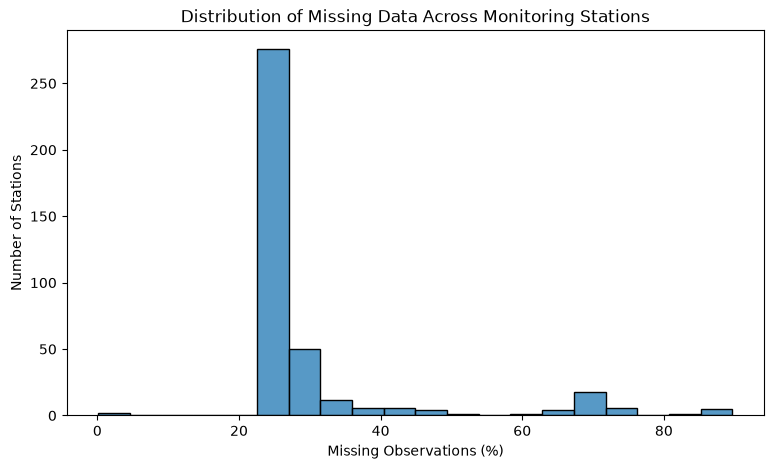

In [7]:
###### MISSING DATA BY STATION ######

# Percentage missing for each station
missing_station = df_avg.drop(columns=["County", "Station_Name", "Observation_ID"]).isna().mean(axis=1) * 100

# Summary statistics
missing_station.describe()

# Number of stations with different amounts of missing data
print("Stations with no missing values:", (missing_station == 0).sum())
print("Stations with over 50% missing:", (missing_station > 50).sum())
print("Stations with 100% missing:", (missing_station == 100).sum())

# Number of stations by percentage of missing data
print("Under 10% missing:", (missing_station < 10).sum())
print("Under 25% missing:", (missing_station < 25).sum())
print("Under 50% missing:", (missing_station < 50).sum())
print("Over 75% missing:", (missing_station > 75).sum())

# Distribution of missing observations across stations
plt.figure(figsize=(9, 5))
sns.histplot(missing_station, bins=20)
plt.xlabel("Missing Observations (%)")
plt.ylabel("Number of Stations")
plt.title("Distribution of Missing Data Across Monitoring Stations")
plt.show()

count    4379.000000
mean       30.635372
std        39.104724
min         3.571429
25%         5.612245
50%         8.928571
75%        24.234694
max        99.744898
dtype: float64

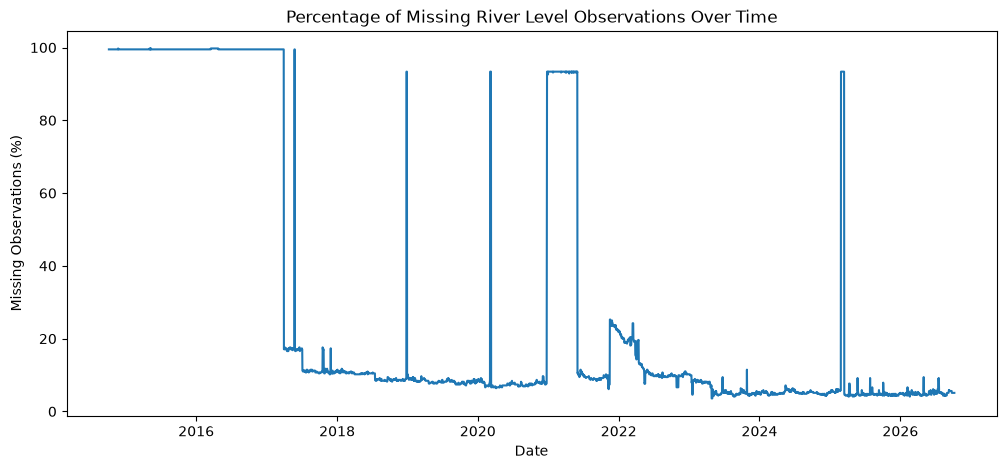

Number of Missing Dates: 8
Missing dates: DatetimeIndex(['2014-10-11', '2014-10-12', '2014-11-26', '2015-04-17',
               '2015-04-22', '2015-05-03', '2015-05-26', '2016-04-06'],
              dtype='datetime64[us]', freq=None)


Year
2014    99.492797
2015    99.491916
2016    99.516354
2017    34.705759
2018    10.406765
Name: Missing (%), dtype: float64

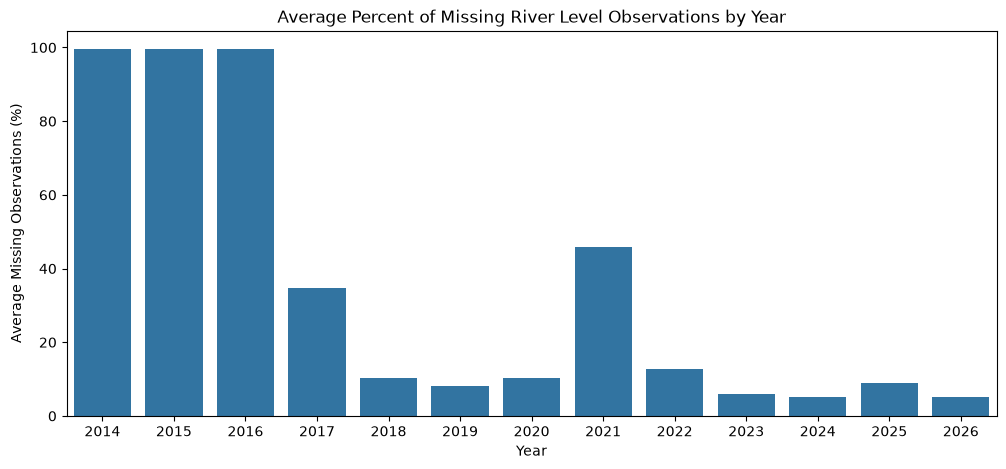

In [8]:
###### MISSING DATA OVER TIME ######
# Percentage missing for each date
missing_date = df_avg.drop(columns=["County", "Station_Name", "Observation_ID"]).isna().mean(axis=0) * 100

# Summary statistics
display(missing_date.describe())

# Convert date labels to datetime for plotting
dates = pd.to_datetime(missing_date.index, dayfirst=True)

# Plot missing observations over time
plt.figure(figsize=(12, 5))
plt.plot(dates, missing_date)
plt.xlabel("Date")
plt.ylabel("Missing Observations (%)")
plt.title("Percentage of Missing River Level Observations Over Time")
plt.show()


# Check for missing calander dates
dates = pd.to_datetime(df_avg.columns[3:], dayfirst=True)

# show complete date range
every_date = pd.date_range(start=dates.min(),end=dates.max())

# find the dates not in the dataset
missing_dates = every_date.difference(dates)
print("Number of Missing Dates:", len(missing_dates))
print("Missing dates:", missing_dates)

# Average percentage of missing obs per yr
missing_by_year = pd.DataFrame({"Year": dates.year, "Missing (%)": missing_date.values})
yearly_missing = missing_by_year.groupby("Year")["Missing (%)"].mean()
display(yearly_missing.head())

# Plot Average percent of missing obs per year

plt.figure(figsize=(12,5))
sns.barplot(x=yearly_missing.index, y=yearly_missing.values)
plt.xlabel("Year")
plt.ylabel("Average Missing Observations (%)")
plt.title("Average Percent of Missing River Level Observations by Year")
plt.show()

0    31/03/2017
1    31/03/2017
2    31/03/2017
3    31/03/2017
4    31/03/2017
dtype: str


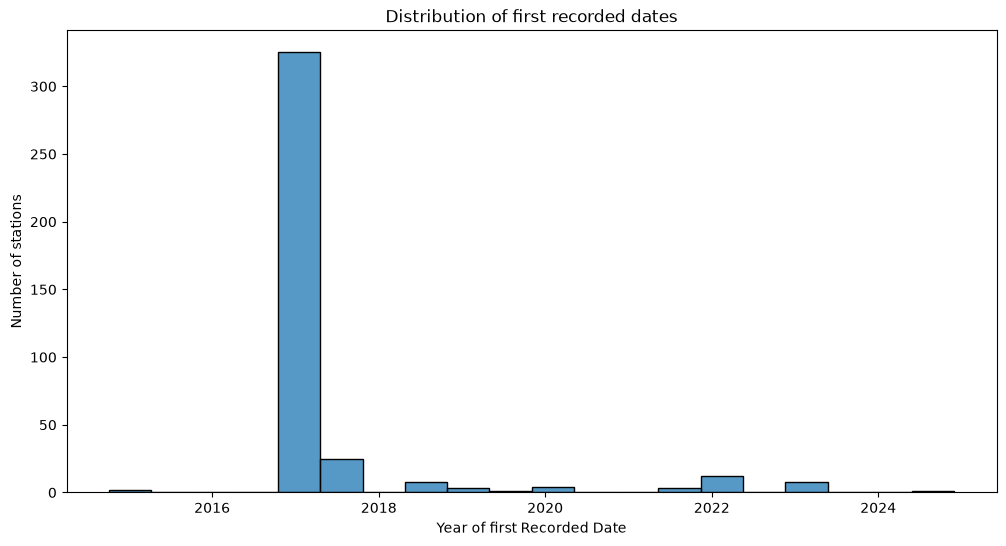

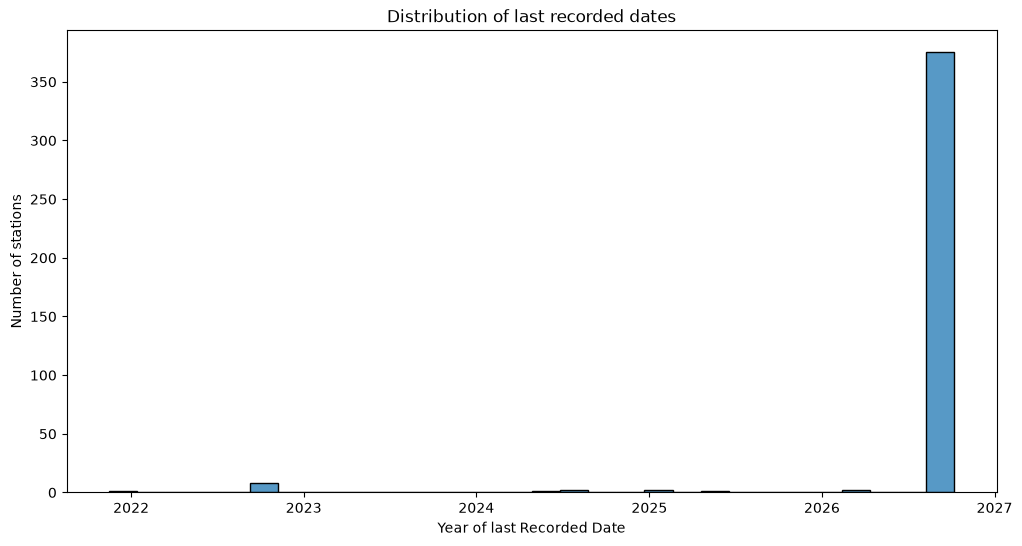

In [9]:
###### STATION RECORDING PERIODS ######

# define function to find first recorded date
def find_first_date(row):
    return row.first_valid_index()

# define function to find last recorded date
def find_last_date(row):
    return row.last_valid_index()

# Select water level measurements
water_levels = df_avg.drop(columns=["County", "Station_Name", "Observation_ID"])

first_date = water_levels.apply(find_first_date, axis=1)
last_date = water_levels.apply(find_last_date, axis=1)

print(first_date.head())

station_start_end = pd.DataFrame({
    "Station": df_avg["Station_Name"],
    "First Date": first_date,
    "Last Date": last_date,
    "Missing (%)": missing_station   
})

plt.figure(figsize=(12,6))
sns.histplot(pd.to_datetime(first_date, dayfirst=True), bins=20)
plt.xlabel("Year of first Recorded Date")
plt.ylabel("Number of stations")
plt.title("Distribution of first recorded dates")
plt.show()

plt.figure(figsize=(12,6))
sns.histplot(pd.to_datetime(last_date, dayfirst=True), bins=30)
plt.xlabel("Year of last Recorded Date")
plt.ylabel("Number of stations")
plt.title("Distribution of last recorded dates")
plt.show()

count     392.000000
mean     3037.477041
std       620.180990
min       452.000000
25%      3146.000000
50%      3283.000000
75%      3293.000000
max      4373.000000
dtype: float64


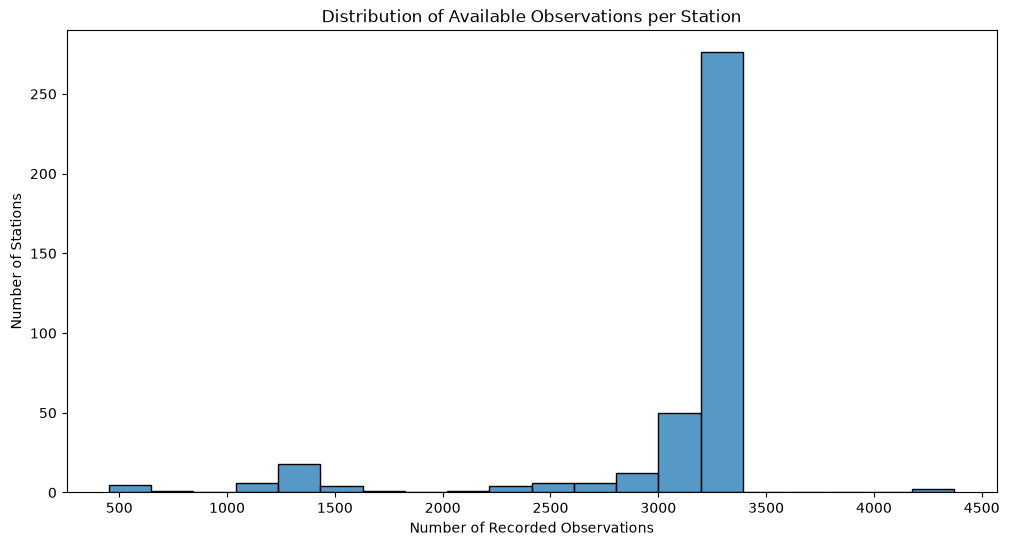

,Station,Observation ID,First Date,Last Date,Number of Observations,Missing Within Period (%)
383,"Dargall Lane, Dargall Lane",wigtown__dargall-lane-dargall-lane__obs1,03/11/2021,08/10/2026,572,68.239867
285,"Newhall Burn, Newhall Bridge",ross-and-cromarty__newhall-burn-newhall-bridge...,14/05/2022,08/10/2026,570,64.574270
244,"Isla (Tayside), Links Farm",perth-and-kinross__links-farm-perth-and-kinros...,05/04/2020,08/10/2026,1227,48.402019
12,"Keithfield Burn, Mill of Keithfield",aberdeenshire__keithfield-burn-mill-of-keithfi...,31/03/2017,19/02/2026,1790,44.889163
20,"Elliot Water, Kelly Den - Arbilot",angus__elliot-water-kelly-den-arbilot__obs1,14/05/2022,16/07/2024,452,43.144654
189,"Carron, Carron upstream (Stonehaven)",kincardineshire__carron-carron-upstream-stoneh...,14/05/2022,12/08/2024,480,41.605839
166,"Loch Oich, Bridge of Oich",inverness__loch-oich-bridge-of-oich__obs1,31/03/2017,15/11/2021,1062,37.196925
13,"Loch Kinord, Meikle Kinord",aberdeenshire__loch-kinord-meikle-kinord__obs1,31/03/2017,08/10/2026,2194,36.935901
202,"Clyde, Kirkfieldbank",lanarkshire__clyde-kirkfieldbank__obs1,31/03/2017,06/11/2022,1296,36.687836
319,"Avondhu Burn, Milton",stirling-and-falkirk__avondhu-burn-milton__obs1,31/03/2017,06/11/2022,1331,34.978017


In [10]:
###### STATION DATA AVAILABILITY ######

num_obs = df_avg.drop(columns=["County", "Station_Name", "Observation_ID"]).count(axis=1)

print(num_obs.describe())

plt.figure(figsize=(12,6))
sns.histplot(num_obs, bins=20)
plt.xlabel("Number of Recorded Observations")
plt.ylabel("Number of Stations")
plt.title("Distribution of Available Observations per Station")
plt.show()

# Create summary table for each station
station_coverage = pd.DataFrame({
    "Station": df_avg["Station_Name"],
    "Observation ID": df_avg["Observation_ID"],
    "First Date": first_date,
    "Last Date": last_date,
    "Number of Observations": num_obs
})

# Define function to calculate missingness within recording period
def missing_within_station(row):
    first = row.first_valid_index()
    last = row.last_valid_index()

    if first is None:
        return 100

    return row.loc[first:last].isna().mean() * 100

# Calculate missingness for each station
missing_inside = water_levels.apply(missing_within_station, axis=1)

# Add results to station coverage table
station_coverage["Missing Within Period (%)"] = missing_inside

# Sort stations by highest internal missingness
station_coverage = station_coverage.sort_values("Missing Within Period (%)", ascending=False)

display(station_coverage.head(20))

In [11]:
###### RIVER LEVEL CHARACTERISTICS

# select avergae river level measurements
water_levels = df_avg.drop(columns=["County", "Station_Name", "Observation_ID"])

# Caclulate summary stats
station_stats = pd.DataFrame({
    "Station": df_avg["Station_Name"],
    "Observation ID": df_avg["Observation_ID"],
    "Number of Observations": water_levels.count(axis=1),
    "Mean": water_levels.mean(axis=1),
    "Median": water_levels.median(axis=1),
    "Standard Deviation": water_levels.std(axis=1),
    "IQR": water_levels.quantile(0.75, axis=1) -
           water_levels.quantile(0.25, axis=1),
    "Minimum": water_levels.min(axis=1),
    "Maximum": water_levels.max(axis=1)
})
print(station_stats.head())
display(station_stats.describe())

# Identify stations that have highest variability
display(station_stats.sort_values("Standard Deviation", ascending=False).head(30))

                      Station                                Observation ID  \
0             Bogie, Redcraig           aberdeenshire__bogie-redcraig__obs1   
1   Dee (Grampian), Mar Lodge   aberdeenshire__dee-grampian-mar-lodge__obs1   
2        Dee (Grampian), Park        aberdeenshire__dee-grampian-park__obs1   
3  Dee (Grampian), Polhollick  aberdeenshire__dee-grampian-polhollick__obs1   
4     Dee (Grampian), Woodend     aberdeenshire__dee-grampian-woodend__obs1   

   Number of Observations      Mean  Median  Standard Deviation      IQR  \
0                    3294  0.329307   0.288            0.204039  0.22875   
1                    3288  0.790073   0.745            0.173137  0.19725   
2                    3292  1.086194   0.982            0.377590  0.39725   
3                    3290  0.584706   0.534            0.212161  0.24675   
4                    3286  0.741292   0.677            0.298935  0.34500   

   Minimum  Maximum  
0    0.013    1.945  
1    0.026    2.048  
2 

,Number of Observations,Mean,Median,Standard Deviation,IQR,Minimum,Maximum
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,3037.477041,4.581932,0.659918,165.717914,0.273099,-987.544824,6224.773727
std,620.180990,42.471968,1.606503,1258.339544,0.155762,11978.959940,55331.797844
min,452.000000,-195.774521,0.030000,0.036390,0.030000,-190475.436000,0.268000
25%,3146.000000,0.358981,0.312500,0.164379,0.171687,-0.013750,1.497000
50%,3283.000000,0.507488,0.443000,0.232741,0.248500,0.000000,2.145500
75%,3293.000000,0.758967,0.630250,0.331480,0.341625,0.019000,2.993500
max,4373.000000,643.502457,29.720000,19706.577031,1.309000,0.948000,999999.999000


,Station,Observation ID,Number of Observations,Mean,Median,Standard Deviation,IQR,Minimum,Maximum
268,"Abhainn Bruachaig, Kinlochewe Lodge",ross-and-cromarty__abhainn-bruachaig-kinlochew...,2575,388.781408,0.3670,19706.577031,0.27650,0.000,999999.999
329,"Endrick Water, Graystone Bridge",stirling-and-falkirk__endrick-water-graystone-...,2814,643.502457,0.3740,12224.320176,0.19475,0.012,307692.995
245,"Leven (Fife), Loch Leven Sluices",perth-and-kinross__leven-fife-loch-leven-sluic...,1340,227.346265,0.2990,4159.917956,0.40425,0.070,118645.205
55,"Garnock, Kilbirnie",ayrshire-and-arran__garnock-kilbirnie__obs1,2997,121.112767,0.5530,3819.324819,0.24100,-7.905,157895.392
379,"Blackwater of Dee, Loch Dee Outlet",wigtown__blackwater-of-dee-loch-dee-outlet__obs1,3283,-84.495120,0.5600,3668.073004,0.43500,-190475.436,3.328
45,"Annick Water, Chapeltoun Gauging Station",ayrshire-and-arran__annick-water__obs1,2757,162.455420,0.4770,3568.949434,0.22300,0.000,109589.604
182,"Spey, Spey Dam",inverness__spey-spey-dam__obs1,3286,-195.774521,2.0080,3092.729821,1.01350,-119562.593,5.517
61,"Kilmarnock Water, Howard Park",ayrshire-and-arran__kilmarnock-water-howard-pa...,3289,52.171044,0.3640,2967.977849,0.20000,0.000,170213.366
170,"Lochy (Lochaber), Gairlochy",inverness__lochy-lochaber__obs1,2473,44.926960,29.7200,2212.543560,0.74700,-76895.519,72943.521
134,"Loch Lomond, Ross Priory",dunbartonshire__loch-lomond-ross-priory__obs1,3276,36.083331,7.9700,1606.558087,0.47150,-24.326,91961.524


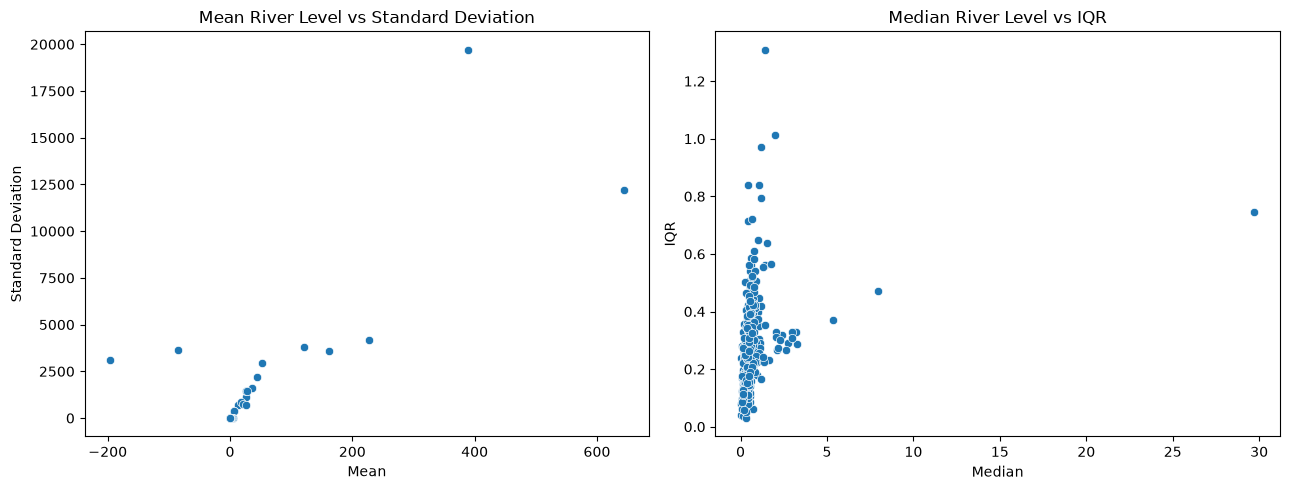

In [12]:
###### VISUALISING TYPICAL LEVELS AND VARIABILITY ######

fig, axes = plt.subplots(1, 2, figsize=(13,5))

# Mean vs standard deviation
sns.scatterplot(
    data=station_stats,
    x="Mean",
    y="Standard Deviation",
    ax=axes[0]
)
axes[0].set_title("Mean River Level vs Standard Deviation")

# Median against IQR
sns.scatterplot(
    data=station_stats,
    x="Median",
    y="IQR",
    ax=axes[1]
)
axes[1].set_title("Median River Level vs IQR")

plt.tight_layout()
plt.show()

In [29]:
###### INVESTIGATING EXTREME VALUES ######

# identify the station with highest SD
station_idx = station_stats["Standard Deviation"].idxmax()
print("Station:", df_avg.loc[station_idx, "Station_Name"])

# find the largest and smallest values at this station
print("Largest Values:")
display(water_levels.loc[station_idx].dropna().nlargest(10))
print("Smallest Values:")
display(water_levels.loc[station_idx].dropna().nsmallest(10))

# Identify the date of the largest measurement
date = water_levels.loc[station_idx].idxmax()

# Retrieve the observation ID
station_id = df_avg.loc[station_idx, "Observation_ID"]

# Compare measurements across datasets
for name, df in [
    ("Minimum", df_min),
    ("Average", df_avg),
    ("Maximum", df_max)
]:
    value = df.set_index("Observation_ID").loc[station_id, date]
    print(name, ":", value)


# Identify potentially extreme measurements
unusual = water_levels.abs() > 15


# Count affected measurements and stations
print("Number of extreme measurements:", unusual.sum().sum())
print("Number of affected stations:", unusual.any(axis=1).sum())

# Identify stations with extreme measurements
extreme_stations = df_avg.loc[unusual.any(axis=1), ["Station_Name", "Observation_ID"]]

display(extreme_stations)

#calculate no of obs where abs val more than 20

Station: Abhainn Bruachaig, Kinlochewe Lodge
Largest Values:


07/09/2021    999999.999
08/03/2021         4.910
23/10/2018         1.739
09/10/2018         1.683
12/01/2026         1.681
16/01/2018         1.613
04/10/2025         1.572
25/11/2024         1.564
31/12/2024         1.483
11/01/2020         1.465
Name: 268, dtype: float64

Smallest Values:


10/06/2021    0.0
11/06/2021    0.0
07/11/2021    0.0
08/11/2021    0.0
09/11/2021    0.0
10/11/2021    0.0
11/11/2021    0.0
12/11/2021    0.0
13/11/2021    0.0
14/11/2021    0.0
Name: 268, dtype: float64

Minimum : 999999.999
Average : 999999.999
Maximum : 999999.999
Number of extreme measurements: 2553
Number of affected stations: 23


,Station_Name,Observation_ID
7,"Don, Alford",aberdeenshire__don-alford__obs1
16,"Urie, Pitcaple",aberdeenshire__urie-pitcaple__obs1
35,"Carradale Water, Dippen",argyll-and-bute__carradale-water-dippen__obs1
39,"Orchy, Glen Orchy",argyll-and-bute__orchy-glen-orchy__obs1
45,"Annick Water, Chapeltoun Gauging Station",ayrshire-and-arran__annick-water__obs1
55,"Garnock, Kilbirnie",ayrshire-and-arran__garnock-kilbirnie__obs1
61,"Kilmarnock Water, Howard Park",ayrshire-and-arran__kilmarnock-water-howard-pa...
100,"Water of Leith, Colinton",city-of-edinburgh__water-of-leith-colinton__obs1
110,"Esk (Solway), Langholm Bridge",dumfries__esk-solway-langholm-bridge__obs1
121,"Nith, Whitesands",dumfries__nith-whitesands__obs1


# Model Fitting and Tuning

*In this section you should detail and motivate your choice of model and describe the process used to refine, tune, and fit that model. You are encouraged to explore different models but you should NOT include a detailed narrative or code of all of these attempts. At most this section should very briefly mention the methods explored and why they were rejected - most of your effort should go into describing the final model you are using and your process for tuning and validating it.*

*This section should include the full implementation of your final model, including all necessary validation. All displayed figures should be described and referenced in the text.*

*You should also include a baseline model of your choice and provide a comparison of your model with the baseline model on the test data. You should briefly describe the baseline model considered.*

# Interpretation, Discussion & Conclusions

*In this section you should provide a general overview of your final clustering and of your final supervised learning model, its performance, and reliability. You should discuss what the implications of your models are in terms of the included features, estimated parameters and relationships, predictive performance, and anything else you think is relevant.*

*This should be written with a target audience of a government official, who understands the monitoring of river levels but may only have university level mathematics (not necessarily postgraduate statistics or machine learning). Your goal should be to highlight to this audience how your model can useful. You should also discuss potential limitations or directions of future improvement of your model.*

*Finally, you should include recommendations on factors that may influence the classification of flood events OR the prediction of future water levels (depending on which question you are answering), which may be useful for the government officials to improve their understanding of floods or water level forecasting, and potentially assist in the development of effective river management and interventions.*

*Keep in mind that a negative result, i.e. a model that does not work well predictively, that is well explained and justified in terms of why it failed will likely receive higher marks than a model with strong predictive performance but with poor or incorrect explanations / justifications.*

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

*Include a list of all references cited in the text.*

In [1]:
# Run the following to render to PDF
!jupyter nbconvert --to pdf project.ipynb

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Writing 29863 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 47131 bytes to project.pdf
